# House Price Prediction

## 1. Problem Definition

The goal of this project is to build a machine learning model that can
predict the price of a property based on its characteristics.

The dataset contains information about properties such as:

- Area
- Number of bedrooms
- Location
- Resale status
- Amenities
- Security features
- Parking
- Appliances
- Other property facilities

The target variable is `Price`.

Because `Price` is a continuous numerical variable, this is a
**supervised learning regression problem**.

### Objective

Build and evaluate machine learning regression models that can
accurately predict property prices for previously unseen properties.

### Target Variable

`Price`

In [124]:
import warnings

warnings.filterwarnings("ignore")

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# File handling
import os

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

print("Libraries imported successfully.")

Libraries imported successfully.


### Loading the Dataset

The house price dataset is obtained directly from Kaggle using `kagglehub`.

Loading the dataset programmatically allows the notebook to reproduce the same data-loading process without manually copying the dataset into the project directory.

In [125]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tusharpaul2001/house-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\Minn Bern\.cache\kagglehub\datasets\tusharpaul2001\house-price-prediction\versions\1


### Loading the Dataset into a DataFrame

After identifying the CSV file, we load it into a Pandas DataFrame for further analysis.

The raw dataset is stored as `df_raw` so that the original data remains available for reference while we perform subsequent cleaning and preprocessing steps.

In [126]:
df_raw = pd.read_csv(
    os.path.join(path, "Mumbai.csv")
)

print("Dataset loaded successfully.")
print(f"Rows    : {df_raw.shape[0]:,}")
print(f"Columns : {df_raw.shape[1]:,}")

Dataset loaded successfully.
Rows    : 7,719
Columns : 40


In [127]:
df_raw.info()

print("\nFirst 10 rows:")
display(df_raw.head(10))

<class 'pandas.DataFrame'>
RangeIndex: 7719 entries, 0 to 7718
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Price                7719 non-null   int64
 1   Area                 7719 non-null   int64
 2   Location             7719 non-null   str  
 3   No. of Bedrooms      7719 non-null   int64
 4   Resale               7719 non-null   int64
 5   MaintenanceStaff     7719 non-null   int64
 6   Gymnasium            7719 non-null   int64
 7   SwimmingPool         7719 non-null   int64
 8   LandscapedGardens    7719 non-null   int64
 9   JoggingTrack         7719 non-null   int64
 10  RainWaterHarvesting  7719 non-null   int64
 11  IndoorGames          7719 non-null   int64
 12  ShoppingMall         7719 non-null   int64
 13  Intercom             7719 non-null   int64
 14  SportsFacility       7719 non-null   int64
 15  ATM                  7719 non-null   int64
 16  ClubHouse            7719 non-null 

,Price,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,RainWaterHarvesting,IndoorGames,ShoppingMall,Intercom,SportsFacility,ATM,ClubHouse,School,24X7Security,PowerBackup,CarParking,StaffQuarter,Cafeteria,MultipurposeRoom,Hospital,WashingMachine,Gasconnection,AC,Wifi,Children'splayarea,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Stadium
0,4850000,720,Kharghar,1,1,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0
1,4500000,600,Kharghar,1,1,1,1,1,0,1,1,0,0,0,0,0,1,0,1,1,1,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0
2,6700000,650,Kharghar,1,1,1,1,1,0,1,1,0,0,1,0,0,1,0,1,1,1,1,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0
3,4500000,650,Kharghar,1,1,1,0,0,1,0,1,0,0,1,0,0,0,0,1,1,1,1,0,0,0,0,0,1,1,0,1,1,1,0,0,0,0,0,1,0
4,5000000,665,Kharghar,1,1,1,0,0,1,0,1,0,0,1,0,0,0,0,1,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0
5,17000000,2000,Kharghar,4,1,1,1,1,1,1,1,0,1,1,0,1,1,1,1,1,1,1,0,0,1,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0
6,12500000,1550,Kharghar,3,1,1,0,0,1,0,0,0,0,1,0,0,0,0,1,1,1,0,0,0,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0
7,10500000,1370,Sector-13 Kharghar,3,1,1,0,0,0,0,1,0,0,1,0,0,0,0,1,1,1,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,1,0
8,10500000,1356,Kharghar,3,1,1,1,1,0,1,1,0,0,1,0,0,1,0,1,1,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0
9,15000000,1680,Kharghar,3,1,1,1,1,1,1,1,1,1,1,0,1,1,1,1,1,1,1,0,0,1,0,1,0,1,1,1,0,1,0,0,0,0,0,0,0


In [128]:
# Display 10 randomly selected rows
df_raw.sample(10, random_state=42)

,Price,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,RainWaterHarvesting,IndoorGames,ShoppingMall,Intercom,SportsFacility,ATM,ClubHouse,School,24X7Security,PowerBackup,CarParking,StaffQuarter,Cafeteria,MultipurposeRoom,Hospital,WashingMachine,Gasconnection,AC,Wifi,Children'splayarea,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Stadium
3386,14500000,780,Dahisar,2,1,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
6862,2000000,560,Nala Sopara,1,1,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
4995,6300000,1480,Dombivali East,3,1,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
132,8500000,1150,Kharghar,2,1,1,1,1,0,1,1,1,0,1,0,0,1,0,1,1,1,1,0,0,0,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0
7501,22000000,1153,Thane West,3,0,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
7684,8400000,930,Kamothe,2,0,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
3194,37000000,1450,Malad West,3,1,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
6372,13100000,1073,Mira Road East,2,0,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
5634,3872999,737,Virar,3,0,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9
6793,17000000,2150,Bandra West,4,1,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9,9


In [129]:
# Statistical summary for numerical variables

display(df_raw.describe())

,Price,Area,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,RainWaterHarvesting,IndoorGames,ShoppingMall,Intercom,SportsFacility,ATM,ClubHouse,School,24X7Security,PowerBackup,CarParking,StaffQuarter,Cafeteria,MultipurposeRoom,Hospital,WashingMachine,Gasconnection,AC,Wifi,Children'splayarea,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Stadium
count,"7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00","7,719.00"
mean,"15,061,652.40",998.41,1.91,0.65,7.50,7.47,7.44,7.44,7.44,7.48,7.40,7.40,7.44,7.40,7.40,7.45,7.40,7.54,7.52,7.54,7.43,7.40,7.40,7.40,7.37,7.40,7.38,7.39,7.43,7.52,7.42,7.45,7.37,7.38,7.38,7.37,7.37,7.38,7.37
std,"20,520,999.90",550.97,0.86,0.48,3.20,3.25,3.33,3.32,3.33,3.25,3.40,3.40,3.33,3.41,3.40,3.30,3.40,3.11,3.14,3.11,3.35,3.41,3.40,3.40,3.46,3.42,3.44,3.43,3.34,3.16,3.37,3.29,3.46,3.45,3.45,3.46,3.46,3.44,3.46
min,"2,000,000.00",200.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,"5,300,000.00",650.00,1.00,0.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00
50%,"9,500,000.00",900.00,2.00,1.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00
75%,"17,000,000.00","1,177.00",2.00,1.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00
max,"420,000,000.00","8,511.00",7.00,1.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00,9.00


In [130]:
# Check for duplicate rows
print("\nDuplicate rows:")
print(df_raw.duplicated().sum())


Duplicate rows:
794


In [131]:
# Count all missing values in the cleaned dataset
total_missing = df_raw.isnull().sum().sum()

print(f"Total missing values: {total_missing:,}")

Total missing values: 0


### Checking the Target Variable for Invalid Values

The target variable is `Price`, so we need to make sure it contains
valid property prices.

A property price should not be zero or negative.

We will therefore check for:

- Zero prices
- Negative prices
- Extremely unusual values

Extreme values are not automatically errors. They may represent
genuinely expensive or inexpensive properties, so we will investigate
them during EDA rather than removing them without evidence.

In [132]:
# Check for invalid property prices

zero_price = (df_raw["Price"] == 0).sum()
negative_price = (df_raw["Price"] < 0).sum()

print(f"Properties with price = 0: {zero_price:,}")
print(f"Properties with negative price: {negative_price:,}")

Properties with price = 0: 0
Properties with negative price: 0


### Final Data Quality Inspection

Before modifying the dataset, we perform one final consolidated
inspection of the important data-quality checks.

We check for missing values, duplicates, invalid prices or areas,
bedroom values, location formatting, and the values used by the
property-feature variables.

The purpose is to identify issues that need to be addressed before
the dataset is cleaned and used for exploratory analysis.

In [133]:
# General data-quality checks

print("DATA QUALITY SUMMARY")
print("=" * 50)

print(f"Rows: {len(df_raw):,}")
print(f"Columns: {df_raw.shape[1]:,}")
print(f"Missing values: {df_raw.isnull().sum().sum():,}")
print(f"Duplicate rows: {df_raw.duplicated().sum():,}")

print("\nPRICE")
print("-" * 50)
print(f"Minimum price: {df_raw['Price'].min():,.2f}")
print(f"Maximum price: {df_raw['Price'].max():,.2f}")
print(f"Zero prices: {(df_raw['Price'] == 0).sum():,}")
print(f"Negative prices: {(df_raw['Price'] < 0).sum():,}")

DATA QUALITY SUMMARY
Rows: 7,719
Columns: 40
Missing values: 0
Duplicate rows: 794

PRICE
--------------------------------------------------
Minimum price: 2,000,000.00
Maximum price: 420,000,000.00
Zero prices: 0
Negative prices: 0


In [134]:
# Count each value for every amenity feature

amenity_columns = [
    col for col in df_raw.columns
    if col not in ["Price", "Area", "Location", "No. of Bedrooms"]
]

amenity_summary = pd.DataFrame({
    "0 (No)": df_raw[amenity_columns].eq(0).sum(),
    "1 (Yes)": df_raw[amenity_columns].eq(1).sum(),
    "9 (Unknown)": df_raw[amenity_columns].eq(9).sum()
})

display(amenity_summary)

,0 (No),1 (Yes),9 (Unknown)
Resale,2724,4995,0
MaintenanceStaff,403,995,6321
Gymnasium,596,802,6321
SwimmingPool,874,524,6321
LandscapedGardens,845,553,6321
JoggingTrack,862,536,6321
RainWaterHarvesting,572,826,6321
IndoorGames,1129,269,6321
ShoppingMall,1145,253,6321
Intercom,888,510,6321


### Investigating the Value `9`

While inspecting the categorical and amenity-related variables, we
noticed that several features contain the values `0`, `1`, and `9`.

For example, variables such as `Gymnasium`, `SwimmingPool`, and
`MaintenanceStaff` contain a large number of `9` values.

At first, the meaning of `9` is not clear. Since these variables
describe the presence or absence of property amenities, a value of `9`
does not appear to represent a meaningful quantity. One possible
interpretation is that `9` is being used to represent information that
was not provided or is unknown.

However, we should not make this assumption without further
consideration.

For now, we will keep the original values unchanged and treat `9` as
an issue to investigate during preprocessing. At that stage, we will
decide how best to handle these values based on their meaning and
their potential impact on the models.

In [135]:
# Create a copy of the original dataset
df = df_raw.copy()

# Remove exact duplicate rows
df = df.drop_duplicates()

# Remove leading/trailing spaces from Location
df["Location"] = df["Location"].str.strip()

In [136]:
# Verify the cleaning

print(f"Original rows: {len(df_raw):,}")
print(f"Cleaned rows: {len(df):,}")
print(f"Rows removed: {len(df_raw) - len(df):,}")
print(f"Remaining duplicates: {df.duplicated().sum():,}")
print(f"Missing values: {df.isnull().sum().sum():,}")

Original rows: 7,719
Cleaned rows: 6,925
Rows removed: 794
Remaining duplicates: 0
Missing values: 0


## Step 4: Exploratory Data Analysis

Exploratory Data Analysis is used to understand the structure of the house price data and identify patterns that may be useful for prediction.

The analysis is divided into three levels:

- **Univariate analysis** examines individual variables and their distributions.
- **Bivariate analysis** examines the relationship between two variables, particularly between individual predictors and `Price`.
- **Multivariate analysis** examines relationships among several numerical variables simultaneously.

The analysis is kept focused on patterns that are relevant to predicting house prices.

### 4.1 Univariate Analysis

Univariate analysis examines individual variables independently.

For this project, the analysis focuses on the distribution of the target variable, `Price`, and the distribution of the categorical property characteristics. This helps establish the range and composition of the dataset before examining relationships between variables.

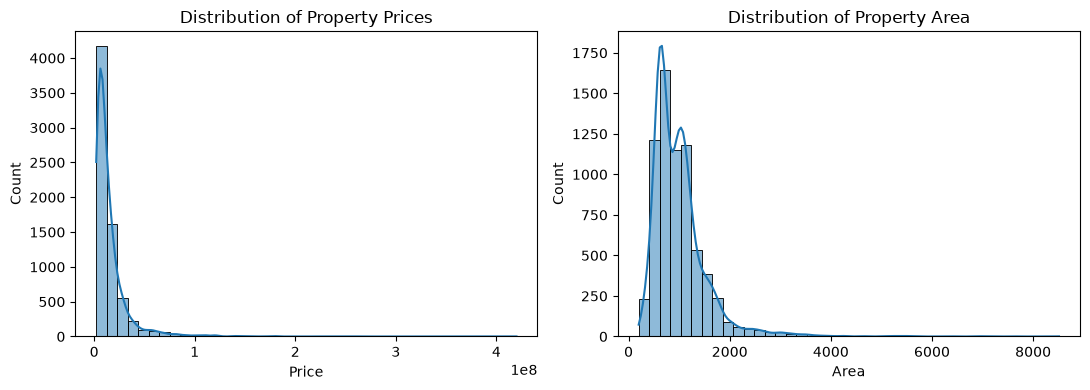

In [137]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Price distribution
sns.histplot(df["Price"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Property Prices")
axes[0].set_xlabel("Price")
axes[0].set_ylabel("Count")

# Area distribution
sns.histplot(df["Area"], bins=40, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Property Area")
axes[1].set_xlabel("Area")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

### Observations on the Distributions

Both `Price` and `Area` show a noticeable right-skewed distribution.
Most observations are concentrated toward the lower end of their
respective ranges, while a smaller number of properties have much
higher prices or larger areas.

These extreme observations should not automatically be considered
errors, since they may represent genuine properties.

The skewness is important for this regression problem because extreme
values can influence model performance. We will therefore keep the
original observations for now and consider whether any transformation
is useful during the preprocessing and modeling stages.

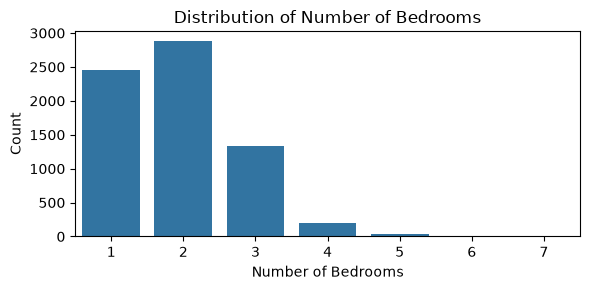

In [138]:
plt.figure(figsize=(6, 3))

sns.countplot(
    data=df,
    x="No. of Bedrooms"
)

plt.title("Distribution of Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

### 4.2 Bivariate Analysis

Bivariate analysis examines the relationship between two variables.

Since the objective of this project is to predict property prices,
we focus on how important property characteristics relate to `Price`.

The analysis focuses on:

- `Area` and `Price`
- `No. of Bedrooms` and `Price`
- `Location` and `Price`

These relationships can help us identify patterns that may be useful
when developing the regression models.

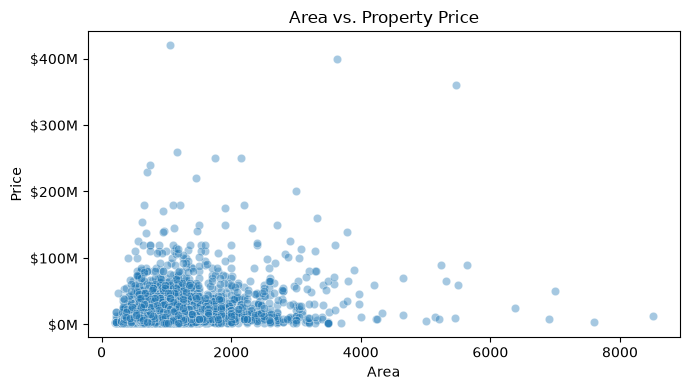

In [139]:
plt.figure(figsize=(7, 4))

sns.scatterplot(
    data=df,
    x="Area",
    y="Price",
    alpha=0.4
)

plt.title("Area vs. Property Price")
plt.xlabel("Area")
plt.ylabel("Price")

# Display price in millions
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x/1e6:.0f}M")
)

plt.tight_layout()
plt.show()

### Observation

The plot suggests that property price generally tends to increase as
property area increases, although the relationship is not perfectly
linear.

Most properties are concentrated within the lower price range, while
a smaller number of properties have substantially higher prices.

There are also some properties with relatively large areas or prices
that are far from the main concentration of observations. These will
be considered further during the modeling stage rather than removed
automatically.

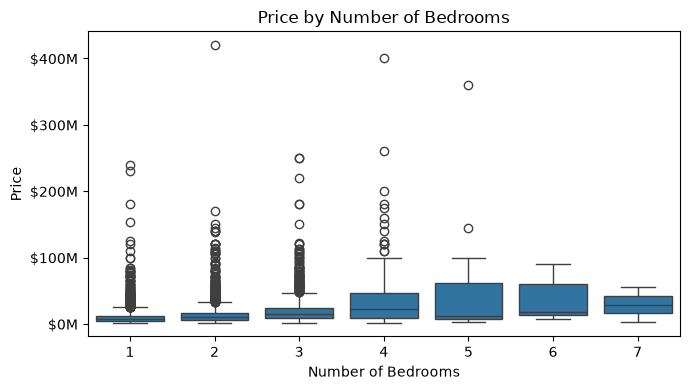

In [140]:
plt.figure(figsize=(7, 4))

sns.boxplot(
    data=df,
    x="No. of Bedrooms",
    y="Price"
)

plt.title("Price by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Price")

# Display price in millions
plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"${x/1e6:.0f}M")
)

plt.tight_layout()
plt.show()

### Observation

The median property price generally increases as the number of
bedrooms increases, particularly from 1 to 4 bedrooms.

However, the price ranges overlap considerably between bedroom
categories. This suggests that the number of bedrooms alone does not
fully explain property price.

The large number of points above several boxes also indicates that
some properties have prices considerably higher than the typical
price within their bedroom category. These observations will be
investigated further rather than removed at this stage.

## 4.3 Multivariate Analysis

Multivariate analysis examines relationships among several variables
at the same time.

A correlation matrix provides an initial view of the relationships
between the numerical variables in the dataset.

We are particularly interested in how the numerical predictors relate
to `Price`.

Correlation is useful for identifying patterns, but it does not
establish causation.

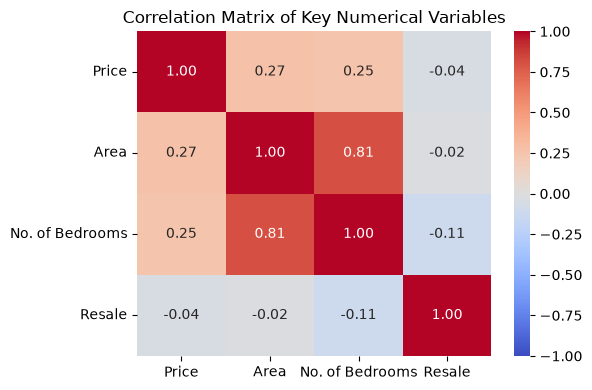

In [141]:
# Select numerical variables with meaningful numerical values
correlation_columns = [
    "Price",
    "Area",
    "No. of Bedrooms",
    "Resale"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    fmt=".2f"
)

plt.title("Correlation Matrix of Key Numerical Variables")
plt.tight_layout()
plt.show()

### Observation

The correlation matrix provides an initial view of the relationships
between the main numerical variables.

`Area` and `Price` are of particular interest because both are
continuous variables and their correlation can provide an indication
of how strongly property size is associated with price.

The amenity variables were not included in this correlation analysis
because their `9` values require further investigation. Treating `9`
as an ordinary numerical value could produce misleading correlation
results.

The correlation values range from -1 to 1, where values closer to 1
indicate a stronger positive linear relationship, values closer to -1
indicate a stronger negative relationship, and values around 0
indicate little linear relationship.

### 4.4 EDA Summary

The exploratory analysis provided an initial understanding of the
property-price dataset.

The distributions of `Price` and `Area` showed noticeable right
skewness, with most observations concentrated toward the lower end
and a smaller number of observations having substantially larger
values.

The bivariate analysis suggested that `Area` has a positive
relationship with `Price`, while property prices also vary across
different bedroom categories and locations.

Several unusually high price observations were identified during the
analysis. These have not been removed because they may represent
genuine properties.

Finally, the amenity variables contain the value `9`, whose meaning
is not completely clear from the data alone. Since treating `9` as a
normal numerical value could produce misleading results, these
variables will be handled carefully during preprocessing.

The findings from EDA will guide the next stage of the project:
preparing the data for machine learning.

# Step 5: Data Preprocessing

Before training machine learning models, the dataset must be
converted into a form that the models can use effectively.

The first step is to separate the target variable, `Price`, from the
predictor variables.

`Price` will be our target (`y`), while the remaining variables will
form the feature matrix (`X`).

In [142]:
# Separate features and target

X = df.drop(columns="Price")
y = df["Price"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (6925, 39)
Target: (6925,)


### 5.2 Handling the Value `9`

During EDA, we observed that several amenity variables contain the
values `0`, `1`, and `9`.

The meaning of `9` cannot be confirmed directly from the dataset.
However, its frequency and its occurrence across many amenity
variables suggest that it may represent information that was not
provided or is unknown.

Rather than assuming that `9` means either `0` or `1`, we will treat
it as missing information during preprocessing.

This allows the preprocessing pipeline to determine how these values
should be represented without introducing an unsupported assumption.

In [143]:
# Amenity columns containing the 9 encoding

amenity_columns = [
    col for col in X.columns
    if 9 in X[col].unique()
]

print(f"Number of amenity columns: {len(amenity_columns)}")
print(amenity_columns)

Number of amenity columns: 35
['MaintenanceStaff', 'Gymnasium', 'SwimmingPool', 'LandscapedGardens', 'JoggingTrack', 'RainWaterHarvesting', 'IndoorGames', 'ShoppingMall', 'Intercom', 'SportsFacility', 'ATM', 'ClubHouse', 'School', '24X7Security', 'PowerBackup', 'CarParking', 'StaffQuarter', 'Cafeteria', 'MultipurposeRoom', 'Hospital', 'WashingMachine', 'Gasconnection', 'AC', 'Wifi', "Children'splayarea", 'LiftAvailable', 'BED', 'VaastuCompliant', 'Microwave', 'GolfCourse', 'TV', 'DiningTable', 'Sofa', 'Wardrobe', 'Stadium']


In [144]:
# Replace the suspected missing-value code with NaN

X[amenity_columns] = X[amenity_columns].replace(9, np.nan)

print(f"Missing values after replacing 9: {X.isnull().sum().sum():,}")

Missing values after replacing 9: 201,915


### 5.3 Train-Test Split

Before applying preprocessing, the dataset is divided into training
and testing sets.

The training set will be used to learn the patterns in the data,
while the test set will be kept aside to evaluate the models on
previously unseen properties.

Keeping the test set separate helps prevent data leakage and gives a
more realistic measure of model performance.

In [145]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print(f"Training features: {X_train.shape}")
print(f"Testing features:  {X_test.shape}")
print(f"Training target:   {y_train.shape}")
print(f"Testing target:    {y_test.shape}")
print(f"Training set: {len(X_train):,} rows ({len(X_train)/len(X)*100:.0f}%)")
print(f"Testing set:  {len(X_test):,} rows ({len(X_test)/len(X)*100:.0f}%)")

Training features: (5540, 39)
Testing features:  (1385, 39)
Training target:   (5540,)
Testing target:    (1385,)
Training set: 5,540 rows (80%)
Testing set:  1,385 rows (20%)


In [146]:
# Numerical features
numerical_features = [
    "Area",
    "No. of Bedrooms"
]

# All remaining predictors will be treated as categorical
categorical_features = [
    col for col in X.columns
    if col not in numerical_features
]

print("Numerical features:")
print(numerical_features)

print(f"\nNumber of categorical features: {len(categorical_features)}")
print(categorical_features)

Numerical features:
['Area', 'No. of Bedrooms']

Number of categorical features: 37
['Location', 'Resale', 'MaintenanceStaff', 'Gymnasium', 'SwimmingPool', 'LandscapedGardens', 'JoggingTrack', 'RainWaterHarvesting', 'IndoorGames', 'ShoppingMall', 'Intercom', 'SportsFacility', 'ATM', 'ClubHouse', 'School', '24X7Security', 'PowerBackup', 'CarParking', 'StaffQuarter', 'Cafeteria', 'MultipurposeRoom', 'Hospital', 'WashingMachine', 'Gasconnection', 'AC', 'Wifi', "Children'splayarea", 'LiftAvailable', 'BED', 'VaastuCompliant', 'Microwave', 'GolfCourse', 'TV', 'DiningTable', 'Sofa', 'Wardrobe', 'Stadium']


### 5.5 Building the Preprocessing Pipeline

The preprocessing steps are placed inside a pipeline so that the same
transformations are applied consistently during model development.

For numerical variables, missing values will be replaced using the
median.

For categorical variables, missing values will be replaced using the
most frequent value. The categorical variables will then be converted
into numerical form using one-hot encoding.

The preprocessing will be fitted using the training data only to avoid
information from the test set influencing the model development
process.

In [147]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing steps
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [148]:
# Fit the preprocessing on the training data
X_train_processed = preprocessor.fit_transform(X_train)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

Original training shape: (5540, 39)
Processed training shape: (5540, 450)


# Step 6: Model Development

With the data prepared, we can now develop regression models for
property-price prediction.

A simple Linear Regression model will provide a baseline for comparison.
We will then compare it with tree-based models that can capture more
complex relationships between the property characteristics and price.

Because model performance can vary depending on which observations are
used for training and validation, we will use 5-fold cross-validation
on the training data.

The test set will remain untouched until the final evaluation.

### 6.1 Regression Models

Three models will be compared:

- **Linear Regression** provides a simple baseline.
- **Random Forest** can capture nonlinear relationships and
  interactions between features.
- **Gradient Boosting** builds models sequentially to improve
  prediction errors from previous models.

Using different model types allows us to determine whether a more
complex model provides an advantage over the linear baseline.

In [149]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=50,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        random_state=42
    )
}

### 6.2 Five-Fold Cross-Validation

The models will be evaluated using 5-fold cross-validation.

The training data is divided into five parts. In each iteration, four
parts are used to train the model and the remaining part is used for
validation.

This process is repeated until every part has been used for validation.

The average performance across the five folds will be used to compare
the models.

The test set remains untouched during this process and will only be
used for the final evaluation.

In [150]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [151]:
model_pipelines = {}

for name, model in models.items():

    model_pipelines[name] = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

### 6.4 Evaluating Models Using Cross-Validation

Each model will now be evaluated using the same five validation folds.

We will record:

- MAE
- RMSE
- R²

MAE and RMSE measure prediction error, where lower values are better.

R² measures how much variation in property prices is explained by the
model, where higher values are better.

In [152]:
cv_results = []

for name, pipeline in model_pipelines.items():

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "MAE": "neg_mean_absolute_error",
            "RMSE": "neg_root_mean_squared_error",
            "R2": "r2"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV MAE": -scores["test_MAE"].mean(),
        "CV RMSE": -scores["test_RMSE"].mean(),
        "CV R²": scores["test_R2"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values("CV RMSE")
)

,Model,CV MAE,CV RMSE,CV R²
2,Gradient Boosting,"9,603,925.96","17,584,067.22",0.13
0,Linear Regression,"9,418,870.31","17,807,507.92",0.11
1,Random Forest,"9,454,148.25","18,510,579.35",0.04


### Cross-Validation Results

The initial cross-validation results show that the three models
perform relatively similarly in terms of MAE and RMSE.

Gradient Boosting produced the lowest RMSE and the highest R² among
the models tested, while Linear Regression produced the lowest MAE.

The relatively low R² values indicate that the initial models explain
only a limited proportion of the variation in property prices.

Therefore, the initial results should be treated as a baseline rather
than the final model. Further evaluation and improvement will be
considered before selecting the final model.

# Step 7: Model Evaluation

Based on the cross-validation results, Gradient Boosting is the
current leading model because it achieved the lowest RMSE and the
highest R².

The model will now be fitted using the complete training set.

The test set has remained untouched throughout model development and
will be used for the first final evaluation on unseen data.

In [153]:
# Select the current best model
best_model_name = "Gradient Boosting"
best_model = model_pipelines[best_model_name]

# Train on the complete training set
best_model.fit(X_train, y_train)

# Predict on the untouched test set
y_pred = best_model.predict(X_test)

print("Model:", best_model_name)
print("Test predictions generated successfully.")

Model: Gradient Boosting
Test predictions generated successfully.


In [154]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

print(f"MAE:  {test_mae:,.2f}")
print(f"RMSE: {test_rmse:,.2f}")
print(f"R²:   {test_r2:.4f}")

MAE:  10,034,352.60
RMSE: 22,611,244.73
R²:   0.0679


### Test Set Results

The Gradient Boosting model was evaluated on the previously untouched
test set.

The model achieved an MAE of approximately $10.03 million and an RMSE
of approximately $22.61 million. The R² score was 0.0679.

The test results are weaker than the cross-validation results,
indicating that the initial model has limited predictive power on
unseen properties.

Therefore, this model will be treated as a baseline rather than the
final solution. Further investigation and improvement will be carried
out before the final model is selected.

# Step 8: Model Improvement

The initial model comparison showed that Gradient Boosting produced the
strongest overall cross-validation performance.

A log transformation of the target variable was also investigated, but
it did not improve the overall RMSE or R².

Hyperparameter tuning was considered, but the expected improvement was
small relative to the added complexity.

Therefore, the original Gradient Boosting model will be retained as
the final candidate for evaluation.

# Step 9: Final Evaluation

The original Gradient Boosting model was selected as the final model
because it produced the strongest overall cross-validation performance
among the initial models tested.

The model will now be evaluated on the untouched test set.

This provides an estimate of how the model performs on properties that
were not used during model development.

In [155]:
# Use the original Gradient Boosting model
final_model = model_pipelines["Gradient Boosting"]

# Generate final predictions on the test set
y_pred_final = final_model.predict(X_test)

print("Final predictions generated successfully.")

Final predictions generated successfully.


### 9.2 Final Model Performance

The final model is evaluated using three regression metrics:

- **MAE** measures the average absolute difference between predicted
  and actual prices.
- **RMSE** gives greater weight to large prediction errors.
- **R²** measures the proportion of variation in property prices
  explained by the model.

Lower MAE and RMSE indicate smaller prediction errors, while a higher
R² indicates better explanatory performance.

In [156]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

final_mae = mean_absolute_error(y_test, y_pred_final)
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred_final))
final_r2 = r2_score(y_test, y_pred_final)

print(f"MAE:  ${final_mae:,.2f}")
print(f"RMSE: ${final_rmse:,.2f}")
print(f"R²:   {final_r2:.4f}")

MAE:  $10,034,352.60
RMSE: $22,611,244.73
R²:   0.0679


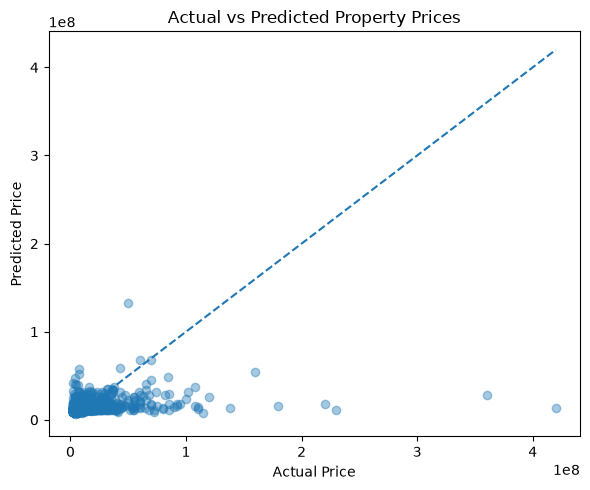

In [ ]:
#Actual vs Predicted Property Prices
plt.figure(figsize=(6, 5))

plt.scatter(
    y_test,
    y_pred_final,
    alpha=0.4
)

# Reference line
min_price = min(y_test.min(), y_pred_final.min())
max_price = max(y_test.max(), y_pred_final.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--"
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Property Prices")

plt.tight_layout()
plt.show()

# Conclusion

This project developed a machine learning model for predicting
property prices using property characteristics, location, and
available amenities.

The dataset was explored and prepared before comparing three
regression approaches: Linear Regression, Random Forest, and Gradient
Boosting.

Gradient Boosting produced the strongest overall cross-validation
performance and was selected as the final model.

On the untouched test set, the model achieved an MAE of approximately
$10.03 million, an RMSE of approximately $22.61 million, and an R² of
0.0679.

These results indicate that the model has limited predictive power.
Although it can identify some patterns in property prices, a large
amount of price variation remains unexplained.

The results also suggest that additional information not available in
the dataset may be important for predicting property prices. Examples
could include more detailed location information, property age,
floor level, property condition, developer, or other market-related
factors.

Therefore, the model should be viewed as a baseline predictive model
rather than a highly accurate property valuation system.